In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### Data Collection & Data Gathering

In [2]:
df = pd.read_csv(r"C:\Users\Sam\Downloads\archive (9)\data_ecommerce_customer_churn.csv")

### Data Inspection & Data Prepration & Data Cleaning

In [3]:
df.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0


In [4]:
df.shape

(3941, 11)

In [5]:
df.isnull().sum()/len(df)*100

Tenure                      4.922608
WarehouseToHome             4.288252
NumberOfDeviceRegistered    0.000000
PreferedOrderCat            0.000000
SatisfactionScore           0.000000
MaritalStatus               0.000000
NumberOfAddress             0.000000
Complain                    0.000000
DaySinceLastOrder           5.404720
CashbackAmount              0.000000
Churn                       0.000000
dtype: float64

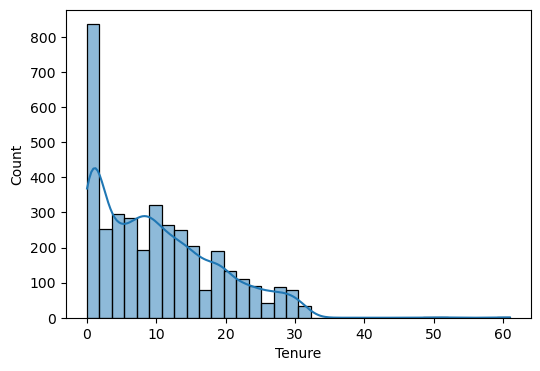

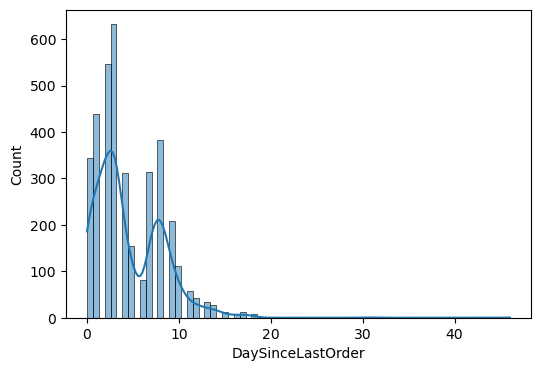

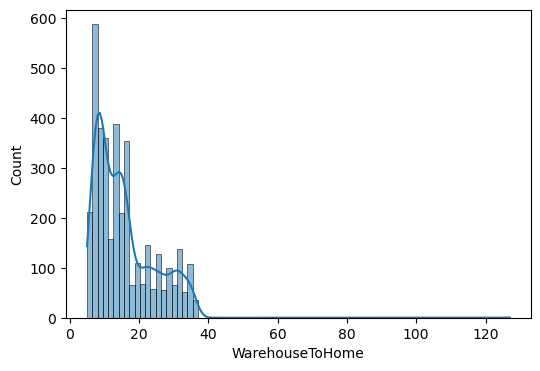

In [6]:
null_col = ['Tenure', 'DaySinceLastOrder', 'WarehouseToHome']

for col in null_col:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True)
    plt.show()

In [7]:
tenure_mean = df['Tenure'].mean()
tenure_median = df['Tenure'].median()

WarehouseToHome_median = df['WarehouseToHome'].median()

DaySinceLastOrder_mode = df['DaySinceLastOrder'].mode()[0]
DaySinceLastOrder_median = df['DaySinceLastOrder'].median()

In [8]:
# filling null values in DaySinceLastOrder 
df['DaySinceLastOrder'] = df['DaySinceLastOrder'].fillna(DaySinceLastOrder_mode)

# WarehouseToHome filling null value with median bcoz it's has swek data
df['WarehouseToHome'] = df['WarehouseToHome'].fillna(WarehouseToHome_median)

# with Tenure column , filling null value with median as well, it also has swe data
df['Tenure'] = df['Tenure'].fillna(tenure_median)

In [9]:
df.isnull().sum()

Tenure                      0
WarehouseToHome             0
NumberOfDeviceRegistered    0
PreferedOrderCat            0
SatisfactionScore           0
MaritalStatus               0
NumberOfAddress             0
Complain                    0
DaySinceLastOrder           0
CashbackAmount              0
Churn                       0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(672)

In [11]:
df = df.drop_duplicates()

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.shape

(3269, 11)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3269 entries, 0 to 3940
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Tenure                    3269 non-null   float64
 1   WarehouseToHome           3269 non-null   float64
 2   NumberOfDeviceRegistered  3269 non-null   int64  
 3   PreferedOrderCat          3269 non-null   object 
 4   SatisfactionScore         3269 non-null   int64  
 5   MaritalStatus             3269 non-null   object 
 6   NumberOfAddress           3269 non-null   int64  
 7   Complain                  3269 non-null   int64  
 8   DaySinceLastOrder         3269 non-null   float64
 9   CashbackAmount            3269 non-null   float64
 10  Churn                     3269 non-null   int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 306.5+ KB


In [15]:
columns_continuous =  ['Tenure', 'WarehouseToHome', 'NumberOfDeviceRegistered',
       'SatisfactionScore', 'NumberOfAddress', 'Complain', 'DaySinceLastOrder',
       'CashbackAmount']

columns_categorical = ['PreferedOrderCat', 'MaritalStatus']

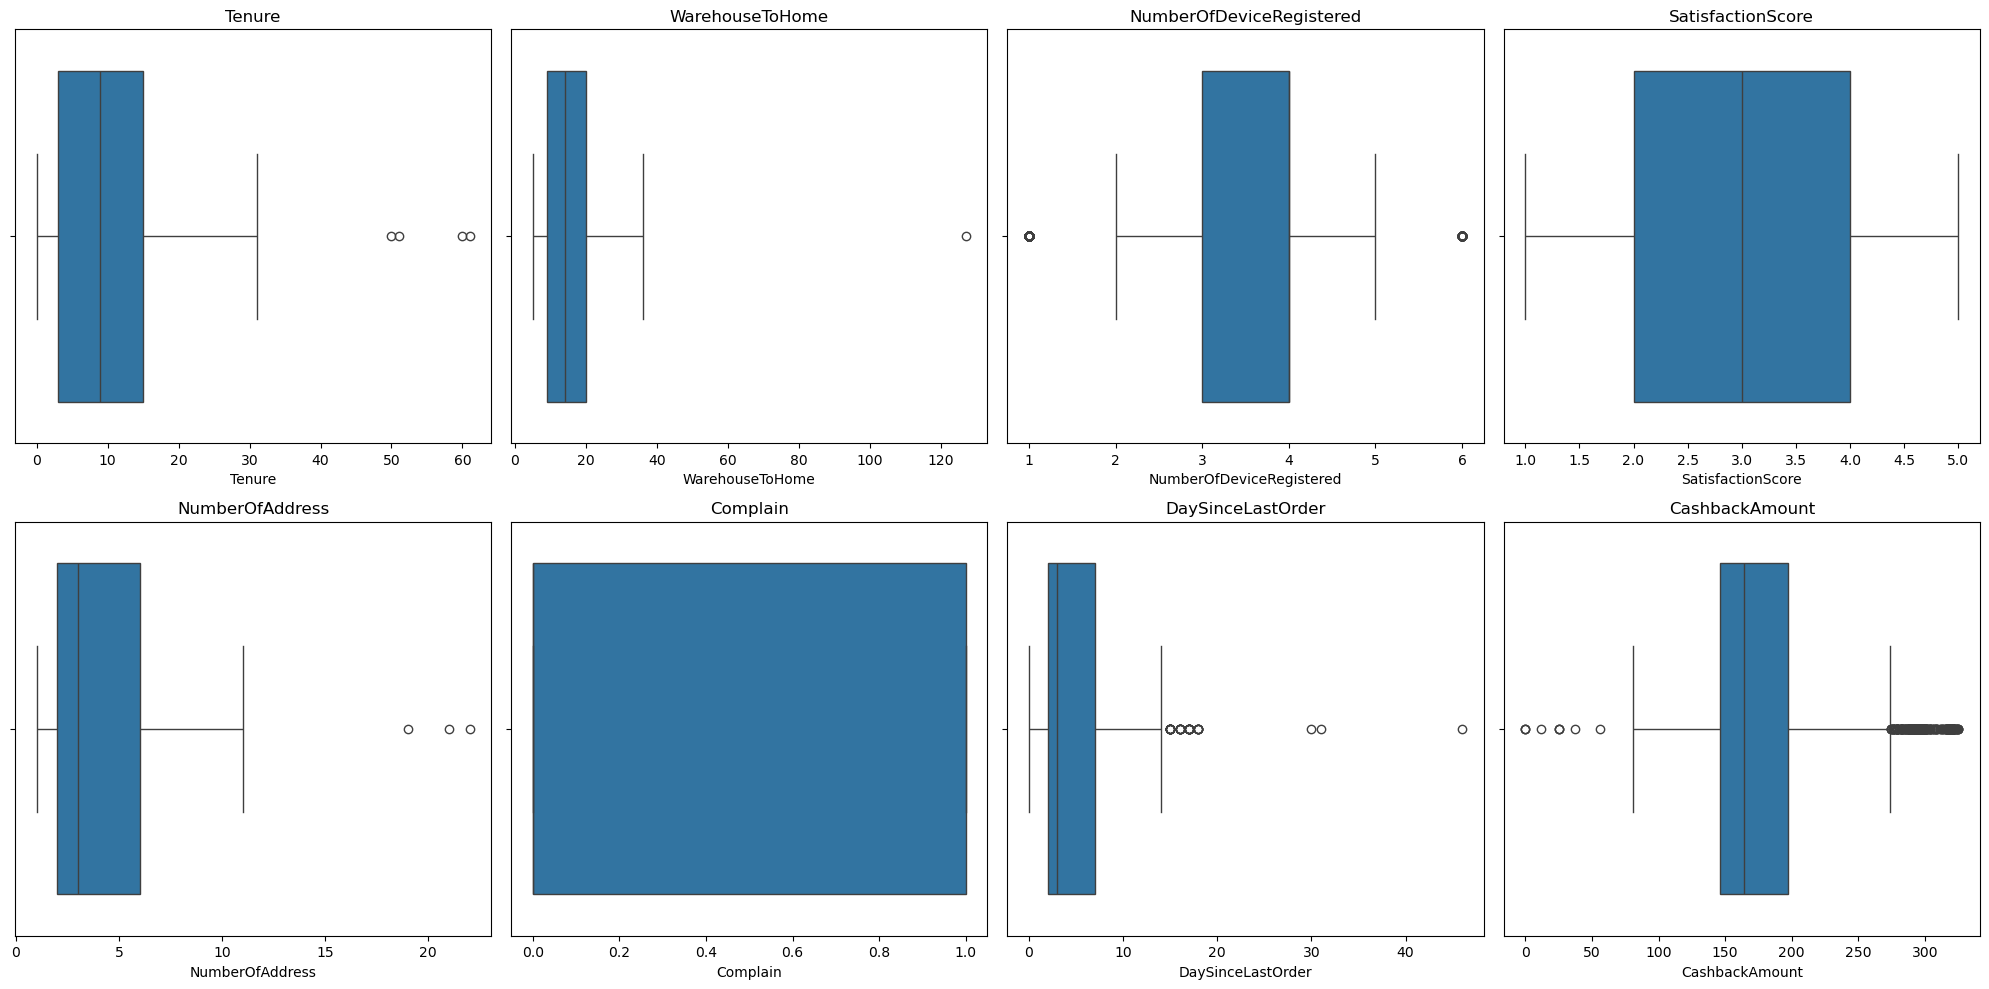

In [16]:
num_plots = len(columns_continuous)
num_cols = 4
num_rows = (num_plots + num_cols -1)//num_cols

fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 5*num_rows))
axes = axes.flatten()

for i, col in enumerate(columns_continuous):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col)

for j in range(i+1, num_rows*num_cols):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

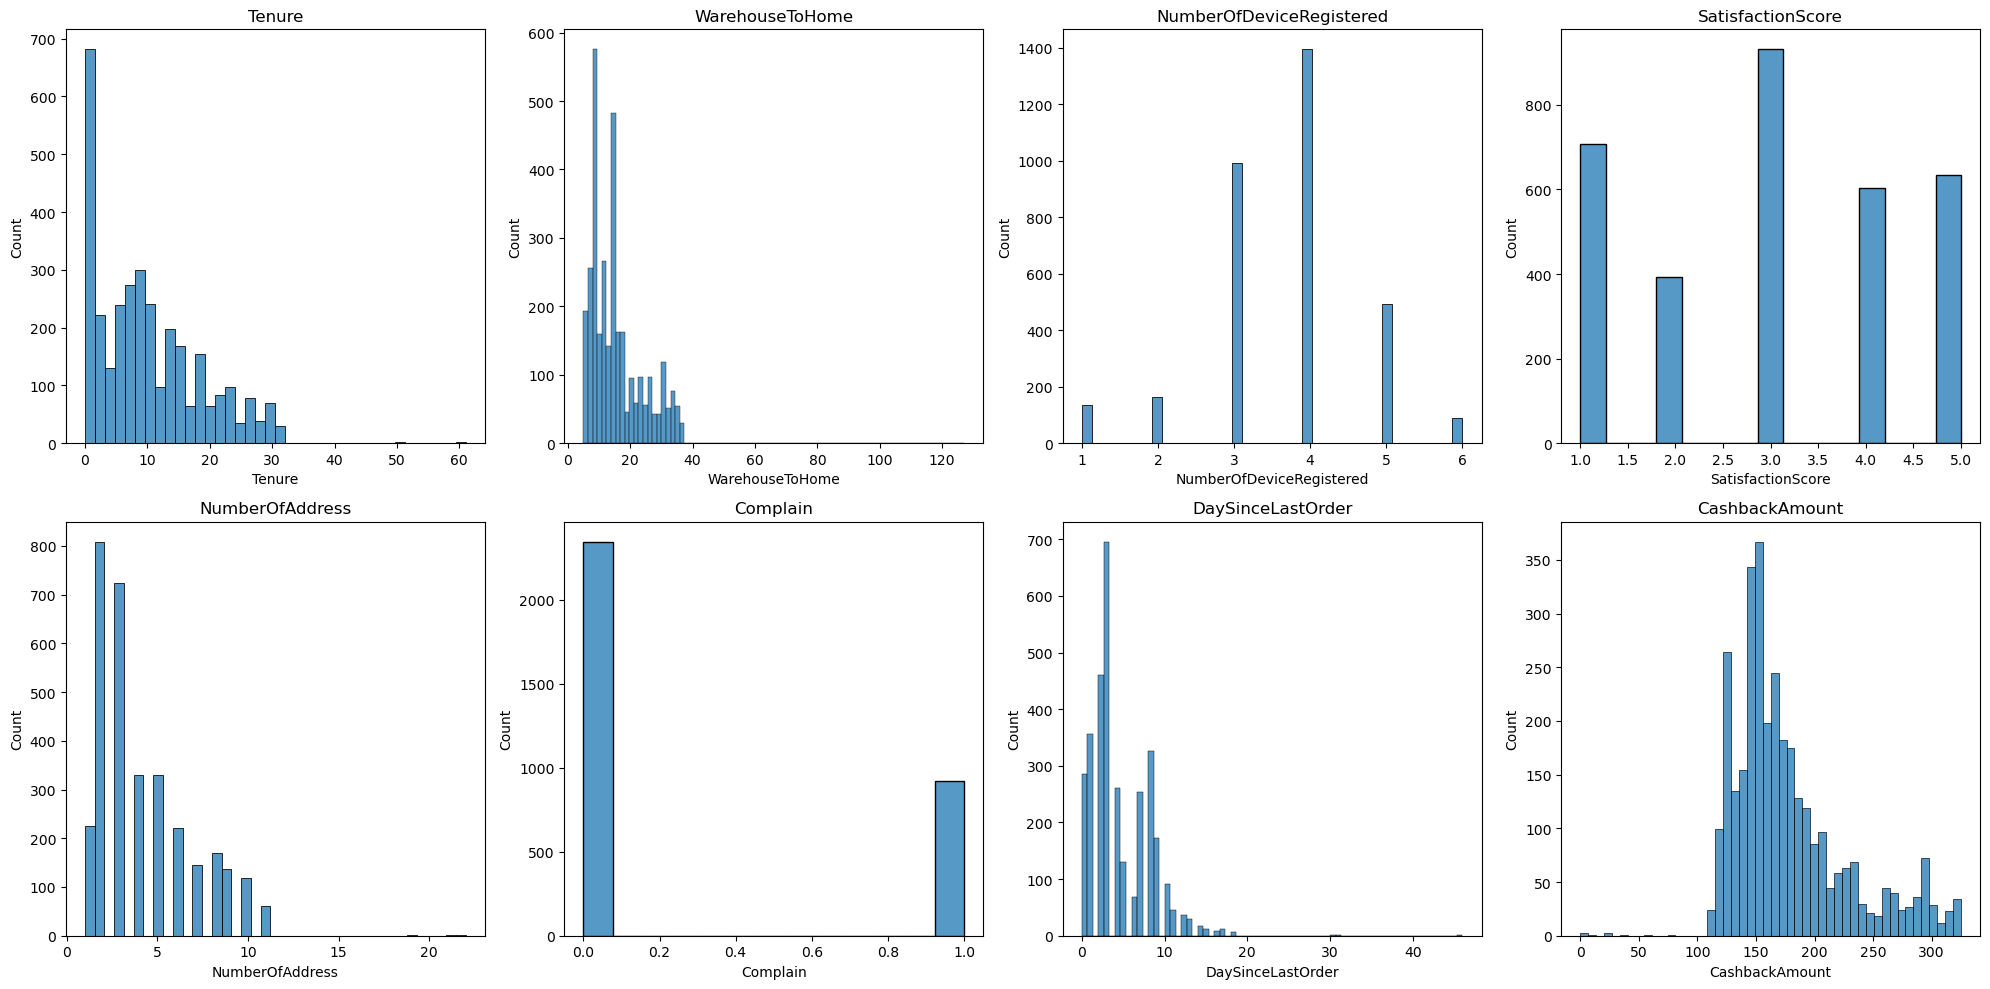

In [17]:
num_plots = len(columns_continuous)
num_cols = 4
num_rows = (num_plots + num_cols -1)//num_cols

fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 5*num_rows))
axes = axes.flatten()

for i, col in enumerate(columns_continuous):
    sns.histplot(x=df[col], ax=axes[i])
    axes[i].set_title(col)

for j in range(i+1, num_rows*num_cols):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

### Categorial Columns

In [18]:
for col in columns_categorical:
    print(col, '==>', df[col].unique())

PreferedOrderCat ==> ['Laptop & Accessory' 'Mobile' 'Fashion' 'Others' 'Mobile Phone' 'Grocery']
MaritalStatus ==> ['Single' 'Married' 'Divorced']


### Feature Engineering 

In [19]:
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, cross_validate

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.metrics import auc, roc_curve, classification_report

In [20]:
X = df.drop(columns=['Churn'], axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

X_train.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount
1911,5.0,14.0,4,Laptop & Accessory,2,Married,6,0,8.0,200.47
823,27.0,13.0,4,Laptop & Accessory,3,Married,4,1,6.0,148.06
3506,11.0,17.0,4,Mobile Phone,4,Married,3,0,8.0,164.36
1064,18.0,8.0,4,Grocery,2,Divorced,10,0,8.0,267.92
1067,21.0,14.0,5,Fashion,5,Married,9,1,3.0,225.08


In [23]:
cols_to_scale = X_train.select_dtypes(['int64', 'float']).columns

scaler = MinMaxScaler()
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_train.describe()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount
count,2615.000000,2615.000000,2615.000000,2615.000000,2615.000000,2615.000000,2615.000000,2615.000000
mean,0.168375,0.085293,0.536597,0.504685,0.154402,0.281836,0.143823,0.547398
std,0.140483,0.069104,0.203346,0.350363,0.125720,0.449980,0.113886,0.153002
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.050000,0.032787,0.400000,0.250000,0.047619,0.000000,0.064516,0.449214
50%,0.150000,0.073770,0.600000,0.500000,0.095238,0.000000,0.096774,0.504754
75%,0.250000,0.122951,0.600000,0.750000,0.238095,1.000000,0.225806,0.610173
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [24]:
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount
count,654.000000,654.000000,654.000000,654.000000,654.000000,654.000000,654.000000,654.000000
mean,0.170489,0.087006,0.529969,0.506881,0.149774,0.281346,0.144125,0.539745
std,0.141343,0.067713,0.204215,0.342764,0.121758,0.450000,0.126291,0.146462
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.076925
25%,0.050000,0.032787,0.400000,0.250000,0.047619,0.000000,0.064516,0.447975
50%,0.150000,0.073770,0.600000,0.500000,0.095238,0.000000,0.096774,0.498892
75%,0.250000,0.120902,0.600000,0.750000,0.226190,1.000000,0.225806,0.592257
max,1.016667,0.254098,1.000000,1.000000,0.476190,1.000000,1.483871,0.995261


In [27]:
X_train_encoded = pd.get_dummies(X_train, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, drop_first=True)

In [30]:
X_train_encoded.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Mobile,PreferedOrderCat_Mobile Phone,PreferedOrderCat_Others,MaritalStatus_Married,MaritalStatus_Single
1911,0.083333,0.073770,0.6,0.25,0.238095,0.0,0.258065,0.616850,False,True,False,False,False,True,False
823,0.450000,0.065574,0.6,0.50,0.142857,1.0,0.193548,0.455583,False,True,False,False,False,True,False
3506,0.183333,0.098361,0.6,0.75,0.095238,0.0,0.258065,0.505739,False,False,False,True,False,True,False
1064,0.300000,0.024590,0.6,0.25,0.428571,0.0,0.258065,0.824395,True,False,False,False,False,False,False
1067,0.350000,0.073770,0.8,1.00,0.380952,1.0,0.096774,0.692575,False,False,False,False,False,True,False


### Model Selection

In [31]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_df = pd.DataFrame()
    vif_df['Column'] = data.columns 
    vif_df['VIF'] = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
    return vif_df

In [33]:
calculate_vif(X_train[cols_to_scale])

,Column,VIF
0,Tenure,3.243884
1,WarehouseToHome,2.385960
2,NumberOfDeviceRegistered,6.547111
3,SatisfactionScore,2.840634
4,NumberOfAddress,2.774436
5,Complain,1.380388
6,DaySinceLastOrder,2.960707
7,CashbackAmount,13.167907


In [35]:
X_train_encoded = X_train_encoded.drop(columns=['CashbackAmount'], axis=1)
X_test_encoded = X_test_encoded.drop(columns=['CashbackAmount'], axis=1)

### Model Training

#### Training 1:
- Logistic regression model
- No handle of class imbalance

In [36]:
model = LogisticRegression(max_iter=10000)
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.98      0.94       553
           1       0.79      0.44      0.56       101

    accuracy                           0.89       654
   macro avg       0.85      0.71      0.75       654
weighted avg       0.89      0.89      0.88       654



In [43]:
from sklearn.model_selection import RandomizedSearchCV

param = {
    'C':np.logspace(-4, 4, 20),
    'solver':['lbfgs', 'saga', 'liblinear', 'newton-cg']
}

log_reg = LogisticRegression(max_iter=10000)

random_search = RandomizedSearchCV(
    estimator=log_reg,
    param_distributions=param,
    n_iter=50,
    scoring='f1',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_encoded, y_train)

print(f"Best Parameter: {random_search.best_params_}")
print(f"Best Score :{random_search.best_score_}")

best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print("Classification Report:- ")
print(classification_report(y_test, y_pred))      

Fitting 3 folds for each of 50 candidates, totalling 150 fits
Best Parameter: {'solver': 'lbfgs', 'C': np.float64(1438.44988828766)}
Best Score :0.5467647058823529
Classification Report:- 
              precision    recall  f1-score   support

           0       0.92      0.96      0.94       553
           1       0.70      0.53      0.61       101

    accuracy                           0.89       654
   macro avg       0.81      0.75      0.77       654
weighted avg       0.88      0.89      0.89       654



#### Training 2:
- XGoost model
- without handle of class imbalance

In [37]:
model_xgb = XGBClassifier()
model_xgb.fit(X_train_encoded, y_train)

y_pred = model_xgb.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.97      0.95       553
           1       0.78      0.67      0.72       101

    accuracy                           0.92       654
   macro avg       0.86      0.82      0.84       654
weighted avg       0.92      0.92      0.92       654



In [44]:
model_xgb = XGBClassifier()

param_dist = {
    'n_estimators':[100, 150, 200, 250, 300],
    'max_depth':[3, 4, 5, 6, 7, 8, 9, 10],
    'learning_rate':[0.01, 0.03, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3],
    'subsample':[0.6, 0.7, 0.8, 0.9, 1.0],
    'scale_pos_weight':[1, 2, 3, 5, 7, 10],
    'reg_alpha':[0.01, 0.1, 0.5, 1.0, 5.0, 10.0], # L1 Regularization
    'reg_lambda':[0.01, 0.1, 0.5, 1.0, 5.0, 10.0] # L2 Regularization
}

random_search_xgb = RandomizedSearchCV(
    estimator=model_xgb,
    param_distributions=param_dist,
    n_iter=100,
    scoring='f1',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)


random_search_xgb.fit(X_train_encoded, y_train)

print(f"Best Parameter: {random_search_xgb.best_params_}")
print(f"Best Score :{random_search_xgb.best_score_}")

best_model = random_search_xgb.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print("Classification Report:- ")
print(classification_report(y_test, y_pred))      

Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best Parameter: {'subsample': 0.9, 'scale_pos_weight': 7, 'reg_lambda': 5.0, 'reg_alpha': 0.1, 'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.15}
Best Score :0.6852130925658629
Classification Report:- 
              precision    recall  f1-score   support

           0       0.97      0.95      0.96       553
           1       0.74      0.81      0.77       101

    accuracy                           0.93       654
   macro avg       0.85      0.88      0.86       654
weighted avg       0.93      0.93      0.93       654



#### Training 3:
- XGoost model
- handle of class imbalance

In [45]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=42)

X_train_rus, y_train_rus = rus.fit_resample(X_train_encoded, y_train)

In [54]:
model = LogisticRegression(**random_search.best_params_)

model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test_encoded)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.78      0.86       553
           1       0.39      0.78      0.52       101

    accuracy                           0.78       654
   macro avg       0.67      0.78      0.69       654
weighted avg       0.87      0.78      0.81       654



In [53]:
from xgboost import XGBClassifier

model = XGBClassifier(**random_search_xgb.best_params_)

model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test_encoded)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.76      0.86       553
           1       0.42      0.93      0.58       101

    accuracy                           0.79       654
   macro avg       0.70      0.85      0.72       654
weighted avg       0.90      0.79      0.82       654



Attempt 3:-
1. Logistic Regression
2. Handle Class Imbalance using SMOTE Tomek

In [49]:
from imblearn.combine import SMOTETomek
smt = SMOTETomek(random_state=42)

X_train_smt, y_train_smt = smt.fit_resample(X_train_encoded, y_train)

In [55]:
model = LogisticRegression(**random_search.best_params_)

model.fit(X_train_smt, y_train_smt)
y_pred = model.predict(X_test_encoded)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.80      0.87       553
           1       0.41      0.76      0.54       101

    accuracy                           0.80       654
   macro avg       0.68      0.78      0.70       654
weighted avg       0.87      0.80      0.82       654



In [51]:
from xgboost import XGBClassifier

model = XGBClassifier(**random_search_xgb.best_params_)
model.fit(X_train_smt, y_train_smt)
y_pred = model.predict(X_test_encoded)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.92      0.94       553
           1       0.64      0.80      0.71       101

    accuracy                           0.90       654
   macro avg       0.80      0.86      0.83       654
weighted avg       0.91      0.90      0.90       654



0.7168184373728355
              precision    recall  f1-score   support

           0       0.97      0.95      0.96       553
           1       0.74      0.81      0.77       101

    accuracy                           0.93       654
   macro avg       0.85      0.88      0.86       654
weighted avg       0.93      0.93      0.93       654

ROC-AUC: 0.9492775679014555
PR-AUC: 0.8446748501506077


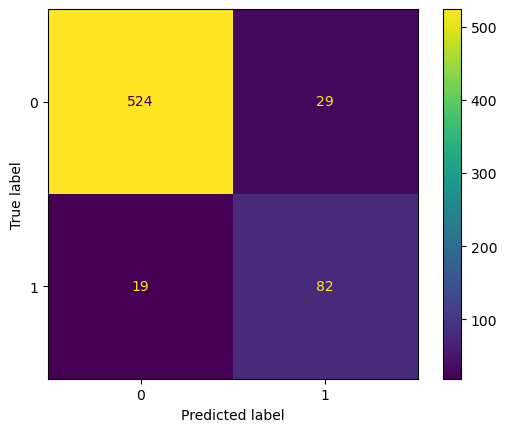

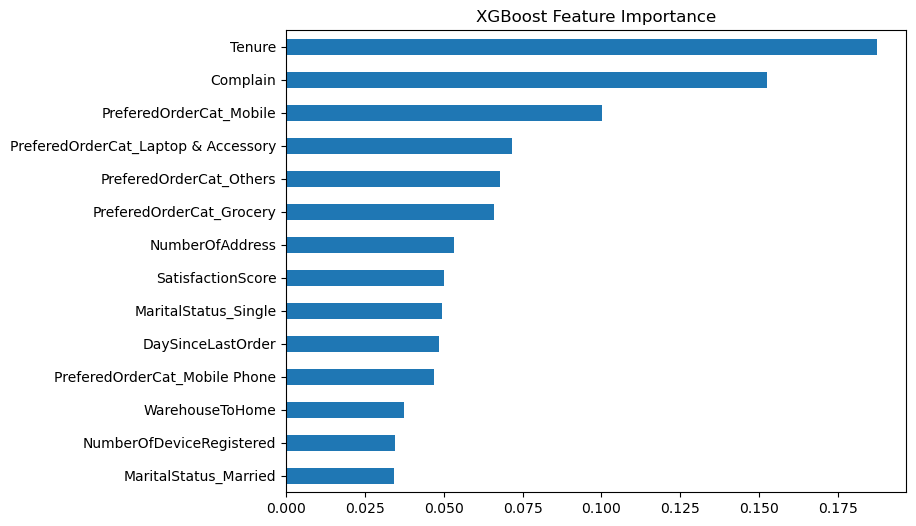

In [61]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

final_model = random_search_xgb.best_estimator_   # tuned XGBoost, no resampling

# cross-validated F1 on training data
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(cross_val_score(final_model, X_train_encoded, y_train, cv=cv, scoring='f1').mean())

# test metrics
y_pred = final_model.predict(X_test_encoded)
y_prob = final_model.predict_proba(X_test_encoded)[:, 1]
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

# confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()
plt.show()

# feature importance
imp = pd.Series(final_model.feature_importances_, index=X_train_encoded.columns).sort_values()
imp.plot(kind='barh', figsize=(8, 6), title='XGBoost Feature Importance')
plt.show()